**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**26 | Final Development Model Training, Reproducible Inference and Qualified Test Gate**

![Stage 26 scientific workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/26_workflow.svg)

**Objective:** Fit the final 1D-ResNet and Random Forest reference on all 29 HARTH Development participants, save and reload the fitted models, and report the separately approved qualified held-out evaluation.

**Dataset:** Pinned HARTH v2.0 recordings with six acceleration channels at 50 Hz, 100-sample label-pure windows, a 50-sample stride and a 500-window-per-participant cap. The 29-person Development cohort contains 14,201 selected windows.

**Notebook Scope:** Sections 01–10 fit models and verify Development-only inference without accessing reserved Test recordings. Sections 11–13 contain the separately authorised, one-time evaluation of 500 windows each from S023 and S032, using the unchanged Development-fitted models.

**Approval and evidence boundary:** The Stage 25 candidate manifest remains `PENDING_USER_REVIEW` as an immutable proposal-time record. Accordingly, the saved Section 08 message `BLOCKED pending explicit user review` describes the Development-only gate, **not** the authorisation status of the subsequent evaluation. Section 11 independently verifies the separate `APPROVED` manifest and explicit Test confirmation before accessing S023 and S032. Both reserved participants had been inspected descriptively earlier, so these completed results are qualified same-study held-out evidence, not blind or external validation.

**00. Colab Repository Setup**

Run the following checkout cell in Colab to prepare the repository. It is separate from the original recorded scientific execution and does not constitute new model evidence.

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")

%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Final Research Environment**

In [2]:
# ================ 01. Imports and Final Research Environment =================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ---------------------------- 2. Standard Library ----------------------------
import json
from pathlib import Path

# ----------------- 3. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 4. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display

# ------------------- 5. Machine Learning and Deep Learning -------------------
from sklearn.ensemble import RandomForestClassifier
import torch

# ---------------- 6. Frozen Models and HARTH Source Utilities ----------------
from core.harth_final_inference import (
    load_final_protocol, fit_final_resnet, fit_development_scaler,
    apply_frozen_scaler, save_final_models, load_final_models,
    infer_source_windows, enforce_qualified_test_approval,
    score_qualified_heldout,
)
from harth_data import (
    HARTH_SUBJECTS, SENSOR_COLUMNS, HARTH_REVISION, ACTIVITY_NAMES,
    prepare_harth_window_cohort,
)
from core.feature_engineering import extract_signal_features

# ------------------------- 7. Scientific Plot Style --------------------------
from core.plot_style import plot_style
plot_style()

# ----------------- 8. Frozen Protocol and Development Cohort -----------------
PROPOSAL=root/"wearable_activity_recognition/evidence/stage_25_protocol_proposal_reconciled.json"
protocol=load_final_protocol(PROPOSAL,root,require_approval=False)
RESERVED_TEST={"S023","S032"}
DEVELOPMENT=sorted(set(HARTH_SUBJECTS)-RESERVED_TEST)
CLASSES=tuple(protocol["source"]["task_codes"])
ARTIFACT_DIR=root/"outputs/harth_stage26_final"
assert len(DEVELOPMENT)==29 and HARTH_REVISION==protocol["source"]["revision"]
assert len(SENSOR_COLUMNS)==6

# ----------------------- 9. GPU and Precision Controls -----------------------
from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type
if DEVICE != "cuda":
    raise RuntimeError("Enable GPU in Colab: Runtime > Change runtime type > GPU.")
torch.set_float32_matmul_precision("highest")
torch.backends.cuda.matmul.allow_tf32=False
torch.backends.cudnn.allow_tf32=False

# ---------------- 10. Research Protocol and Approval Summary -----------------
print(""+"="*70)
print("STAGE 26 | SAFE FINAL DEVELOPMENT MODEL FIT")
print("="*70)
print("Source revision:",HARTH_REVISION)
print("Protocol approval status:",protocol["status"])
print("Reserved Test loaded: NO")


Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.11.0+cu128
CUDA device: Tesla T4
CUDA runtime: 12.8
cuDNN version: 91900
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
STAGE 26 | SAFE FINAL DEVELOPMENT MODEL FIT
Source revision: dad2cfbe89a26f72f19770419469ac037de200df
Protocol approval status: PENDING_USER_REVIEW
Reserved Test loaded: NO


**02. Original 29-Person Development Cohort and Source Integrity**

Construct the exact source-row-aligned 500-cap cohort from the official pinned recordings, applying strict time continuity and label-purity checks **before** filtering out-of-task annotations. Do not use `S023` or `S032` for fitting, feature extraction, batch-normalisation statistics, class weights or architecture decisions. The manifest's Development SHA256 is compared with the exact reconstructed sample used in Stages 23–25.

In [3]:
# ====== 02. Original 29-Person Development Cohort and Source Integrity =======

# ------------ 1. Recreate the bounded Development source windows -------------
X_dev,y_dev,dev_metadata,dev_overview=prepare_harth_window_cohort(
    subjects=DEVELOPMENT,data_dir=root/"data/raw/harth_v2",
    task_classes=CLASSES,max_windows_per_subject=500,
    window_size=100,step_size=50,sampling_rate=50,
)
assert X_dev.shape==(14201,6,100)
assert len(y_dev)==len(dev_metadata)
assert set(dev_metadata["subject_id"])==set(DEVELOPMENT)
assert not(set(dev_metadata["subject_id"])&RESERVED_TEST)

# ---------------- 2. Import the shared fingerprinting utility ----------------
from core.temporal_benchmark import make_benchmark_plan

# --------------- 3. Verify the Development source fingerprint ----------------
dev_plan=make_benchmark_plan(
    X_dev,y_dev,dev_metadata["subject_id"].to_numpy(),
    classes=CLASSES,n_splits=3,forbidden_subjects=RESERVED_TEST,
)
assert dev_plan["fingerprint"]==protocol["source_development_sha256"]
display(dev_overview[["subject_id","eligible_windows","sampled_windows"]])
print("Development SHA256 verified:",dev_plan["fingerprint"])
print("Actual Test source files opened: NO")


Downloaded 59,108,125 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Downloaded 60,603,857 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Downloaded 22,408,603 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Downloaded 50,898,931 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 sa

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Downloaded 22,728,229 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Downloaded 16,070,724 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Downloaded 15,031,875 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Downloaded 14,899,779 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Reje

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Downloaded 15,185,213 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)


,subject_id,eligible_windows,sampled_windows
0,S006,6708,500
1,S008,7392,500
2,S009,201,201
3,S010,6077,500
4,S012,7309,500
5,S013,6402,500
6,S014,6299,500
7,S015,7453,500
8,S016,6272,500
9,S017,6678,500


Development SHA256 verified: 672d4109727a20ea30f2557f6b405445fce86be1898a58851fa976f8ed8bf297
Actual Test source files opened: NO


**03. Development-Only Channel Scaling and Source Class Weights**

The six original sensor axes must remain in the same order in every training and inference window. Channel statistics are calculated from *all final Development windows only*, not from the protected Test. Weighted Cross-Entropy receives Train-only class weights based on actual original activity codes. These parameters are not tuned using held-out observations.

In [4]:
# ======= 03. Development-Only Channel Scaling and Source Class Weights =======

# --------------- 1. Fit channel scaling using Development only ---------------
scaler=fit_development_scaler(X_dev)
X_scaled=apply_frozen_scaler(X_dev,scaler)
assert X_scaled.shape==X_dev.shape and np.isfinite(X_scaled).all()
stats=pd.DataFrame({
    "channel":SENSOR_COLUMNS,
    "development_mean":scaler["mean"],
    "development_std":scaler["std"],
})
display(stats.round(6))

# ---------------- 2. Report the Development activity support -----------------
source_counts=pd.Series(y_dev).value_counts().reindex(CLASSES,fill_value=0)
display(pd.DataFrame({
    "source_code":CLASSES,
    "activity":[ACTIVITY_NAMES[c] for c in CLASSES],
    "development_windows":source_counts.to_numpy(),
}))
assert (source_counts>0).all()


,channel,development_mean,development_std
0,back_x,-0.884657,0.423905
1,back_y,-0.020551,0.221160
2,back_z,-0.135460,0.383786
3,thigh_x,-0.654180,0.679575
4,thigh_y,-0.087987,0.405604
5,thigh_z,-0.440445,0.706797


,source_code,activity,development_windows
0,1,Walking,3591
1,2,Running,1028
2,3,Shuffling,219
3,4,Stairs ascending,192
4,5,Stairs descending,182
5,6,Standing,2227
6,7,Sitting,5599
7,8,Lying,1163


**04. Train the Final 1D-ResNet Using the Frozen 400-Update Procedure**

A newly initialised 1D-ResNet trains on the entire eligible Development cohort using seed 42, batch size 128, Adam 0.001 and inverse-square-root class weighting. It is deliberately trained for exactly 400 optimiser updates and the last-step weights are retained. There is no Validation or Test-driven checkpoint selection. The training loss trace is a diagnostic, **not** an unbiased accuracy estimate.

  Final 1D-ResNet: step 1/400 | Train loss=1.9961
  Final 1D-ResNet: step 100/400 | Train loss=0.3066
  Final 1D-ResNet: step 200/400 | Train loss=0.0779
  Final 1D-ResNet: step 300/400 | Train loss=0.0969
  Final 1D-ResNet: step 400/400 | Train loss=0.1291


,step,development_train_loss
0,1,1.996078
1,100,0.306587
2,200,0.077936
3,300,0.096873
4,400,0.129093


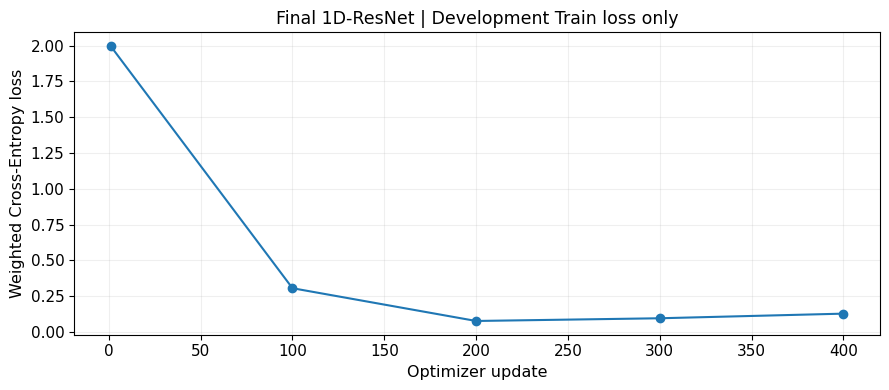

Final model fit duration (seconds): 13.85
Test data used in training: NO


In [5]:
# ==== 04. Train the Final 1D-ResNet Using the Frozen 400-Update Procedure ====

# ------------------- 1. Train the fixed 400-update ResNet --------------------
model,trained_scaler,train_history,class_weights,train_time=fit_final_resnet(
    X_dev,y_dev,protocol,device=DEVICE
)

# ------------- 2. Check the training budget and plot Train loss --------------
assert int(train_history["step"].iloc[-1])==400
display(train_history)
fig,ax=plt.subplots(figsize=(9,4))
ax.plot(train_history["step"],train_history["development_train_loss"],marker="o")
ax.set(title="Final 1D-ResNet | Development Train loss only",
       xlabel="Optimizer update",ylabel="Weighted Cross-Entropy loss")
ax.grid(alpha=.2)
fig.tight_layout()
plt.show()
print("Final model fit duration (seconds):",round(train_time,2))
print("Test data used in training: NO")


**05. Fit the Frozen Random Forest as a Classical Reference**

The Random Forest reference uses 30 deterministic features from the same eligible Development source windows. Feature extraction independently summarises each six-channel window and does not fit a Test-derived transform. The 120-tree specification is frozen from Stage 25, not selected after seeing Test performance.

In [6]:
# ========= 05. Fit the Frozen Random Forest as a Classical Reference =========

# ------------- 1. Extract 30 ordered features per source window --------------
features=extract_signal_features(X_dev,channel_names=SENSOR_COLUMNS)
assert features.shape==(14201,30)

# ------------- 2. Fit the 120-tree Random Forest on Development --------------
rf=RandomForestClassifier(
    n_estimators=120,min_samples_leaf=3,
    class_weight="balanced_subsample",random_state=42,n_jobs=-1
)
rf.fit(features.to_numpy(),y_dev)
assert set(rf.classes_)==set(CLASSES)
print("RF trees:",len(rf.estimators_))
print("RF feature count:",rf.n_features_in_)
print("RF Train subjects:",len(DEVELOPMENT))
print("RF Test subjects accessed: NO")


Input windows: (14201, 6, 100)
Feature matrix: (14201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
RF trees: 120
RF feature count: 30
RF Train subjects: 29
RF Test subjects accessed: NO


**06. Save Model Artefacts and Inference Metadata**

Save the ResNet weights, Development-fitted channel statistics, Random Forest reference, original class mapping, feature-column order and source/protocol fingerprints. Model artefacts must be reloaded only from a trusted local directory; they do not contain the original Test labels or recordings.

In [7]:
# ============== 06. Save Model Artefacts and Inference Metadata ==============

artifact_info=save_final_models(
    model,trained_scaler,rf,list(features.columns),
    protocol,dev_plan["fingerprint"],ARTIFACT_DIR
)
display(pd.DataFrame([
    {"artifact":name,"path":path,"sha256":artifact_info["sha256"][name]}
    for name,path in artifact_info.items() if name!="sha256"
]))
print("Model artefacts stored locally:",ARTIFACT_DIR)
print("Artefacts are ignored by Git and should not be committed.")


,artifact,path,sha256
0,resnet,/content/human-movement-intelligence/outputs/h...,b7a579c60cc6692566939b1250e1d8683653bd879ee92e...
1,reference,/content/human-movement-intelligence/outputs/h...,658a5ea1e2195b0c3631629649a47f89ed9bced1eea8f7...
2,config,/content/human-movement-intelligence/outputs/h...,f4d02dc5f9e2e9a9387de47690d7c342f58343c929a68c...


Model artefacts stored locally: /content/human-movement-intelligence/outputs/harth_stage26_final
Artefacts are ignored by Git and should not be committed.


**07. Reload Models and Verify Development Predictions**

Reload both saved models and their preprocessing configuration, then run inference on 24 Development windows. Confirm that the RF predictions match the in-memory reference and that both reloaded models return valid source activity codes. This is an engineering round-trip check, not an evaluation of performance on unseen participants.

In [8]:
# =========== 07. Reload Models and Verify Development Predictions ============

# ------------- 1. Reload models from the trusted local directory -------------
loaded_model,loaded_rf,config=load_final_models(ARTIFACT_DIR,device="cpu")
N_CHECK=24
unseen_style_windows=X_dev[:N_CHECK]
reloaded_nn,reloaded_rf=infer_source_windows(
    unseen_style_windows,loaded_model,loaded_rf,config,device="cpu"
)

# ------------ 2. Check source codes and RF prediction consistency ------------
assert len(reloaded_nn)==len(reloaded_rf)==N_CHECK
assert set(reloaded_nn).issubset(CLASSES)
assert set(reloaded_rf).issubset(CLASSES)
direct_rf=rf.predict(
    features.iloc[:N_CHECK].to_numpy()
)
np.testing.assert_array_equal(reloaded_rf,direct_rf)
display(pd.DataFrame({
    "true_dev_code":y_dev[:N_CHECK],
    "reloaded_resnet_prediction":reloaded_nn,
    "reloaded_rf_prediction":reloaded_rf,
}))
print("Saved neural and classical inference: PASSED")
print("Independent Test model performance assessed: NO")


Input windows: (24, 6, 100)
Feature matrix: (24, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length


,true_dev_code,reloaded_resnet_prediction,reloaded_rf_prediction
0,1,6,6
1,6,6,6
2,6,6,6
3,6,6,6
4,6,6,6
5,6,6,6
6,6,6,6
7,6,6,6
8,6,6,6
9,6,6,6


Saved neural and classical inference: PASSED
Independent Test model performance assessed: NO


**08. Approval Gate Without Test Access**

This checkpoint deliberately uses the historical `PENDING_USER_REVIEW` candidate and does not load or score S023 or S032. Its saved `BLOCKED` message is **correct for this earlier Development-only checkpoint** and must not be changed to `APPROVED`. It does not contradict the completed evaluation: Section 11 separately checks the subsequently `APPROVED` frozen manifest, verifies the trusted Development artefacts and requires explicit Test confirmation before the one-time qualified assessment.

In [9]:
# =================== 08. Approval Gate Without Test Access ===================

# --------------- 1. Report the initial proposal approval state ---------------
print("Protocol status:",protocol["status"])
print("Qualified Test requested in this notebook: NO")
if protocol["status"]!="APPROVED":
    print("Qualified Test gate: BLOCKED pending explicit user review.")
else:
    print("Qualified Test gate: approval recorded; separate confirmation still required.")

# -------------- 2. Confirm the reserved Test identity boundary ---------------
assert RESERVED_TEST=={"S023","S032"}
print("S023 and S032 recordings read in this notebook: NO")


Protocol status: PENDING_USER_REVIEW
Qualified Test requested in this notebook: NO
Qualified Test gate: BLOCKED pending explicit user review.
S023 and S032 recordings read in this notebook: NO


**09. Qualified Test Reporting Contract**

Before the separately authorised evaluation, specify the fixed eight-class Macro F1, secondary accuracy metrics, per-class precision/recall/F1 and support, participant-level reporting and confusion matrices. This section defines the reporting requirements; it does not calculate Test scores.

In [10]:
# =================== 09. Qualified Test Reporting Contract ===================

report_plan=pd.DataFrame([
    {"evaluation":"Primary metric","requirement":"Fixed eight-class Macro F1"},
    {"evaluation":"Secondary metrics","requirement":"Balanced accuracy and overall accuracy"},
    {"evaluation":"Per-class diagnostics","requirement":"Precision, recall, F1, actual support"},
    {"evaluation":"Independent people","requirement":"S023 and S032 reported separately"},
    {"evaluation":"Model comparison","requirement":"Frozen ResNet and predeclared RF reference"},
    {"evaluation":"Forbidden operations","requirement":"No Test-driven refitting, model choice or hyperparameter search"},
    {"evaluation":"Scientific limitation","requirement":"Originally descriptively inspected; same-study, not external"},
])
display(report_plan)
print("Test metrics created by this stage: NONE")


,evaluation,requirement
0,Primary metric,Fixed eight-class Macro F1
1,Secondary metrics,Balanced accuracy and overall accuracy
2,Per-class diagnostics,"Precision, recall, F1, actual support"
3,Independent people,S023 and S032 reported separately
4,Model comparison,Frozen ResNet and predeclared RF reference
5,Forbidden operations,"No Test-driven refitting, model choice or hype..."
6,Scientific limitation,Originally descriptively inspected; same-study...


Test metrics created by this stage: NONE


**10. Development Fitting Quality Gate**

Verify the 29-person Development cohort, source fingerprints, final ResNet training budget, RF configuration, saved metadata and trusted inference round-trip. At this checkpoint, the reserved recordings have not been opened. Test approval and evaluation are separate, subsequent steps.

In [11]:
# =================== 10. Development Fitting Quality Gate ====================

# ------------- 1. Verify the Development cohort and final models -------------
assert X_dev.shape==(14201,6,100)
assert set(dev_metadata["subject_id"])==set(DEVELOPMENT)
assert not(set(dev_metadata["subject_id"])&RESERVED_TEST)
assert protocol["primary_model"]["optimizer_steps"]==400
assert train_history["step"].iloc[-1]==400
assert len(class_weights)==8 and np.isfinite(class_weights).all()
assert all(Path(path).is_file() for name,path in artifact_info.items() if name!="sha256")

# --------------- 2. Check saved preprocessing and RF inference ---------------
assert config["source_codes"]==list(CLASSES)
assert config["sensor_columns"]==SENSOR_COLUMNS
assert config["preprocessing_fit_scope"]=="Development only"
assert not config["test_fitted_values"]
np.testing.assert_array_equal(reloaded_rf,direct_rf)

# --------------- 3. Report Development fitting and gate status ---------------
print(""+"="*70)
print("STAGE 26 | FROZEN DEVELOPMENT FIT AND INFERENCE ARTEFACTS")
print("="*70)
print("Frozen 29-person Development cohort: VERIFIED")
print("Primary 1D-ResNet trained: YES, 400 fixed updates")
print("Fixed Random Forest trained: YES, 120 trees")
print("Train-only scaler, class map and channel order: SAVED")
print("Trusted artifact reloading/inference: PASSED")
print("Original S023/S032 Test accessed: NO")
print("-"*70)
print("Stage 26 Development training/inference quality gate: PASSED")
print("Protocol approval status:",protocol["status"])
print("Qualified Test evaluation performed: NO")
print("Next: explicit qualified-Test approval and separate gated scoring")


STAGE 26 | FROZEN DEVELOPMENT FIT AND INFERENCE ARTEFACTS
Frozen 29-person Development cohort: VERIFIED
Primary 1D-ResNet trained: YES, 400 fixed updates
Fixed Random Forest trained: YES, 120 trees
Train-only scaler, class map and channel order: SAVED
Trusted artifact reloading/inference: PASSED
Original S023/S032 Test accessed: NO
----------------------------------------------------------------------
Stage 26 Development training/inference quality gate: PASSED
Protocol approval status: PENDING_USER_REVIEW
Qualified Test evaluation performed: NO
Next: explicit qualified-Test approval and separate gated scoring


**11. Approved One-Time Qualified Test Inference**

This saved section records the separately approved evaluation under the unchanged Stage 25 protocol. Before accessing S023 or S032, the code checks the approved manifest against the candidate protocol and verifies the previously saved Development-fitted artefacts.

Exactly 500 eligible windows from each reserved participant are prepared with the fixed settings and scored by both frozen models. Neither Test labels nor Test metrics are used to update preprocessing, weights, hyperparameters, thresholds or model choice. Do not rerun this evaluation for model selection.

In [12]:
# ============== 11. Approved One-Time Qualified Test Inference ===============

# ----------------------- 1. Hashing and JSON Utilities -----------------------
import hashlib
import json

# ------------------ 2. Approved Frozen Inference Utilities -------------------
from core.harth_final_inference import (
    sha256_file, load_final_protocol, enforce_qualified_test_approval,
    load_final_models, infer_source_windows, TEST_CONFIRMATION,
)

# ------------------- 3. Qualified Test Reporting Utilities -------------------
from core.harth_qualified_test_report import (
    validate_final_test_inputs, summarise_qualified_heldout,
    SOURCE_CLASSES, RESERVED_PEOPLE, FINAL_MODELS,
)

# ------------- 4. Verify separate approval against the candidate -------------
approved_path = root / "wearable_activity_recognition/evidence/stage_25_protocol_approved_qualified_test.json"
approved = load_final_protocol(approved_path, root, require_approval=True)
assert approved["approval_record"]["scope"].startswith("One-time qualified")
assert approved["source_development_sha256"] == protocol["source_development_sha256"]
assert approved["primary_model"] == protocol["primary_model"]
assert approved["reference_model"] == protocol["reference_model"]
assert approved["source"] == protocol["source"]
assert approved["evaluation"] == protocol["evaluation"]
assert approved["module_sha256"] == protocol["module_sha256"]
assert enforce_qualified_test_approval(approved, TEST_CONFIRMATION)

# ----------- 5. Validate and reload trusted Development artefacts ------------
expected_artifacts = ["resnet_state_dict.pt", "random_forest.joblib", "inference_config.json"]
for filename in expected_artifacts:
    assert (ARTIFACT_DIR / filename).is_file(), (
        f"Missing Development artefact {filename}; recover trusted files or "
        "rerun the unchanged Development-only Sections 01–10."
    )
assert approved["source_development_sha256"] == dev_plan["fingerprint"]
assert config["development_cohort_sha256"] == approved["source_development_sha256"]
assert config["sensor_columns"] == SENSOR_COLUMNS
assert config["source_codes"] == list(SOURCE_CLASSES)
assert config["preprocessing_fit_scope"] == "Development only"
assert not config["test_fitted_values"]
assert all(sha256_file(artifact_info[key]) == artifact_info["sha256"][key]
           for key in ("resnet", "reference", "config"))
frozen_nn, frozen_rf, frozen_config = load_final_models(ARTIFACT_DIR, device="cpu")
assert frozen_config == config
print("Approved protocol and trusted Development artefacts: VERIFIED")

# ------------- 6. Prepare the authorised held-out source windows -------------
X_test, y_test, test_metadata, test_overview = prepare_harth_window_cohort(
    subjects=list(RESERVED_PEOPLE),
    data_dir=root / "data/raw/harth_v2",
    task_classes=tuple(SOURCE_CLASSES),
    max_windows_per_subject=approved["source"]["test_cap_per_person"],
    window_size=approved["source"]["window_size"],
    step_size=approved["source"]["step_size"],
    sampling_rate=approved["source"]["sampling_rate_hz"],
)
assert X_test.ndim == 3 and X_test.shape[1:] == (6, 100)
assert len(y_test) == len(test_metadata) and len(y_test) <= 1000
assert set(test_metadata["subject_id"]) == set(RESERVED_PEOPLE)
assert not set(test_metadata["subject_id"]).intersection(DEVELOPMENT)
assert all(test_overview["sampled_windows"].between(1, 500))
assert np.isfinite(X_test).all()

# ------------- 7. Score both frozen models without Test fitting --------------
pred_resnet, pred_rf = infer_source_windows(
    X_test, frozen_nn, frozen_rf, frozen_config, device="cpu"
)
predictions = {
    "1D-ResNet Weighted CE": pred_resnet,
    "Random Forest": pred_rf,
}
y_checked, subject_checked, predictions, code_order = validate_final_test_inputs(
    y_test, test_metadata["subject_id"].to_numpy(), predictions
)
display(test_overview[["subject_id", "eligible_windows", "sampled_windows"]])
print("Qualified Test windows:", len(y_checked))
print("Models evaluated: both frozen Development models")
print("Test-driven training, calibration, threshold tuning: NONE")


Approved protocol and trusted Development artefacts: VERIFIED
Downloaded 12,061,722 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S023.csv
HARTH subject S023: 137,646 rows, 6 sensors
Input signal: 137,646 samples, 6 channels
Candidate windows: 2,751
Retained windows: 2,567 | Shape: (2567, 6, 100)
Rejected candidates: 184
Downloaded 14,821,095 bytes to /content/human-movement-intelligence/data/raw/harth_v2/S032.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (2,018 rows in S032.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S032: 178,341 rows, 6 sensors
Input signal: 178,341 samples, 6 channels
Candidate windows: 3,565
Retained windows: 3,038 | Shape: (3038, 6, 100)
Rejected candidates: 527
Temporal cohort: 2 subjects, X=(1000, 6, 100)
Input windows: (1000, 6, 100)
Feature matrix: (1000, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length


,subject_id,eligible_windows,sampled_windows
0,S023,2567,500
1,S032,3037,500


Qualified Test windows: 1000
Models evaluated: both frozen Development models
Test-driven training, calibration, threshold tuning: NONE


**12. Frozen Qualified Test Results**

Report both predeclared models on identical source windows, with fixed eight-class Macro F1, observed-class balanced accuracy, class-specific precision/recall/F1/support, participant-level scores and confusion matrices. Keep absent activities explicit in the class report.

These descriptive results come from only two previously inspected, same-study participants; the selected primary model remains 1D-ResNet with weighted Cross-Entropy regardless of the RF comparison.

FINAL QUALIFIED SAME-STUDY HELD-OUT EVALUATION
Primary model selected on Development: 1D-ResNet Weighted CE
The Test comparison DOES NOT select a replacement.


,model,windows,subjects,fixed_eight_class_macro_f1,balanced_accuracy_observed_classes,accuracy,true_classes_present
0,1D-ResNet Weighted CE,1000,2,0.7182,0.9234,0.902,8
1,Random Forest,1000,2,0.6817,0.7599,0.927,8


,model,subject_id,windows,true_classes_present,fixed_eight_class_macro_f1,balanced_accuracy_observed_classes,accuracy
0,1D-ResNet Weighted CE,S023,500,8,0.7384,0.9559,0.900
1,1D-ResNet Weighted CE,S032,500,6,0.5662,0.8509,0.904
2,Random Forest,S023,500,8,0.7391,0.8376,0.956
3,Random Forest,S032,500,6,0.4597,0.6826,0.898


,model,source_code,activity,precision,recall,f1,support
0,1D-ResNet Weighted CE,1,Walking,0.9959,0.8941,0.9422,538
1,1D-ResNet Weighted CE,2,Running,0.9348,1.0000,0.9663,86
2,1D-ResNet Weighted CE,3,Shuffling,0.1364,1.0000,0.2400,3
3,1D-ResNet Weighted CE,4,Stairs ascending,0.4444,0.8000,0.5714,10
4,1D-ResNet Weighted CE,5,Stairs descending,0.2143,1.0000,0.3529,6
5,1D-ResNet Weighted CE,6,Standing,0.9888,0.6929,0.8148,127
6,1D-ResNet Weighted CE,7,Sitting,0.7516,1.0000,0.8582,115
7,1D-ResNet Weighted CE,8,Lying,1.0000,1.0000,1.0000,115
8,Random Forest,1,Walking,0.9773,0.9610,0.9691,538
9,Random Forest,2,Running,1.0000,1.0000,1.0000,86


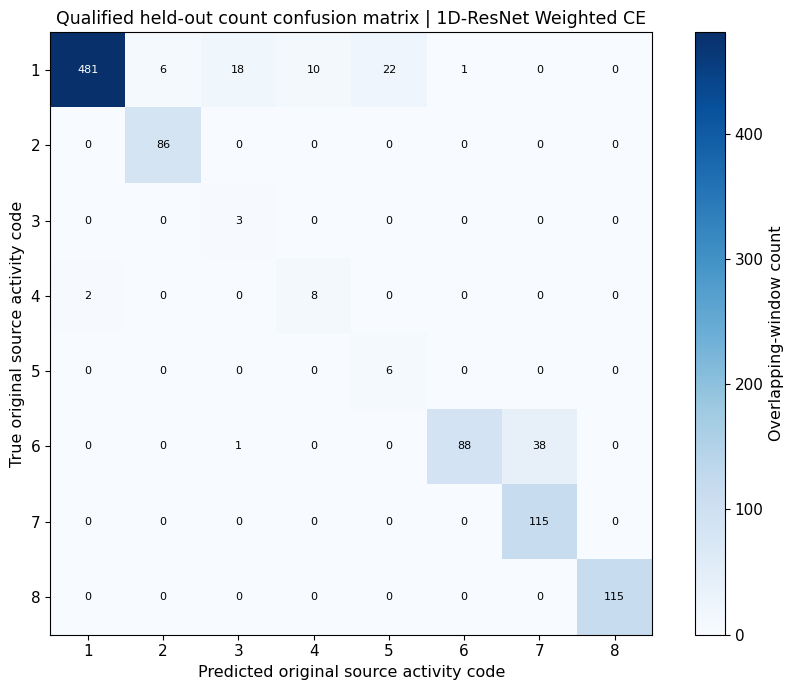

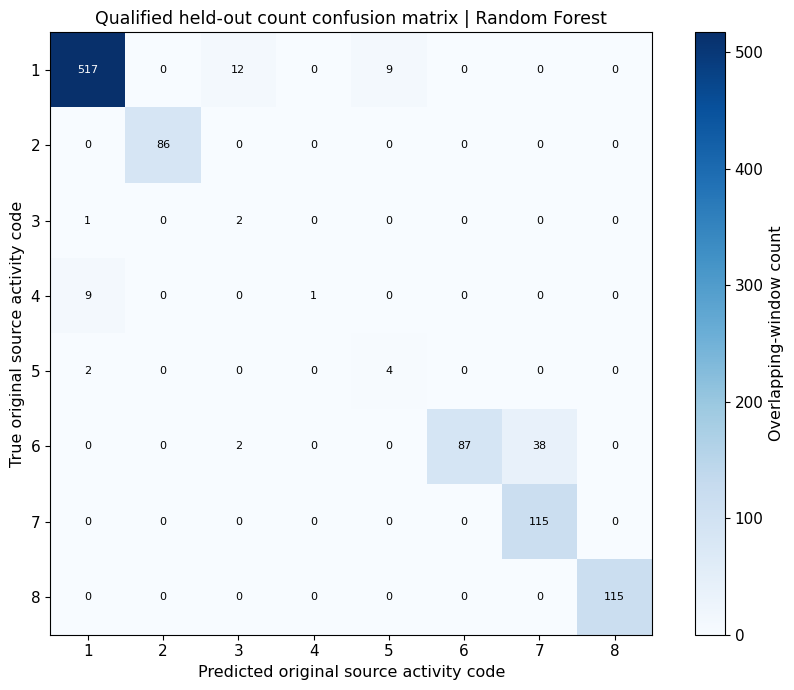

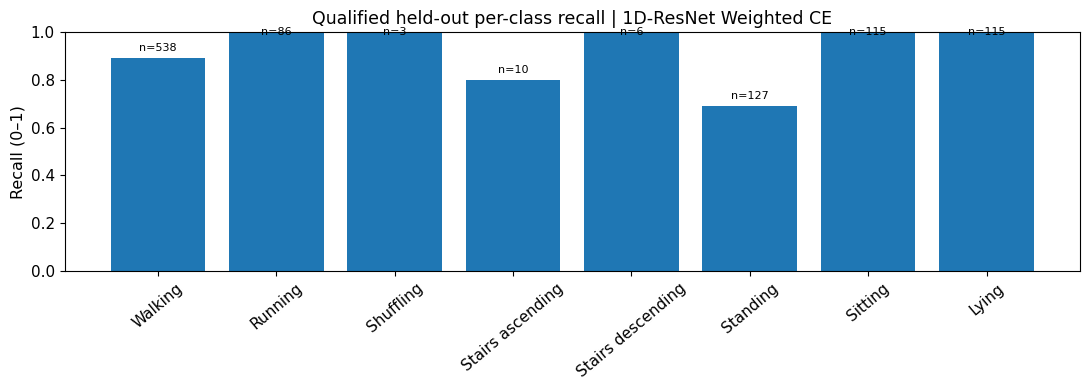

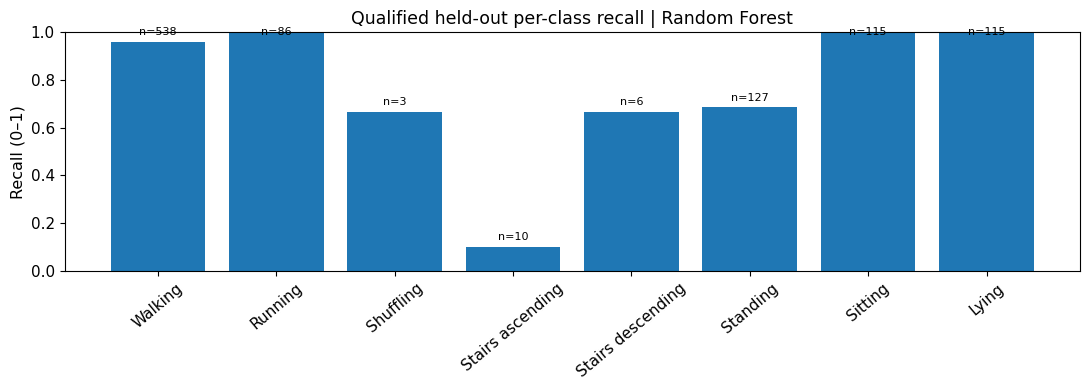

In [13]:
# ===================== 12. Frozen Qualified Test Results =====================

# --------------- 1. Calculate the predefined held-out metrics ----------------
report = summarise_qualified_heldout(
    y_checked, subject_checked, predictions, ACTIVITY_NAMES, SOURCE_CLASSES
)
print("FINAL QUALIFIED SAME-STUDY HELD-OUT EVALUATION")
print("Primary model selected on Development: 1D-ResNet Weighted CE")
print("The Test comparison DOES NOT select a replacement.")
display(report["summary"].round(4))
display(report["per_subject"].round(4))
display(report["per_class"].round(4))

# ------------------ 2. Plot eight-class confusion matrices -------------------
for model_name in FINAL_MODELS:
    cm = report["confusion"][model_name]
    fig, ax = plt.subplots(figsize=(9, 7))
    image = ax.imshow(cm, interpolation="nearest", cmap="Blues")
    ax.set_xticks(range(8), [str(code) for code in SOURCE_CLASSES])
    ax.set_yticks(range(8), [str(code) for code in SOURCE_CLASSES])
    ax.set_xlabel("Predicted original source activity code")
    ax.set_ylabel("True original source activity code")
    ax.set_title(f"Qualified held-out count confusion matrix | {model_name}")
    for row in range(8):
        for column in range(8):
            ax.text(column, row, str(int(cm[row, column])),
                    ha="center", va="center", fontsize=8,
                    color="white" if cm[row, column] > 0.5 * cm.max() else "black")
    fig.colorbar(image, ax=ax, label="Overlapping-window count")
    fig.tight_layout()
    plt.show()

# ----------------- 3. Plot class recall with actual support ------------------
for model_name in FINAL_MODELS:
    subset = report["per_class"].query("model == @model_name").copy()
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.bar(subset["activity"], subset["recall"])
    ax.set_ylim(0, 1)
    ax.set_ylabel("Recall (0–1)")
    ax.set_title(f"Qualified held-out per-class recall | {model_name}")
    ax.tick_params(axis="x", rotation=40)
    for idx, row in enumerate(subset.itertuples()):
        ax.text(idx, min(row.recall + 0.02, 0.98), f"n={row.support}",
                ha="center", va="bottom", fontsize=8)
    fig.tight_layout()
    plt.show()


**13. Final Qualified Evaluation Gate**

Check the approved manifest, frozen artefact hashes, both reserved participant identities, aligned source rows and saved class- and person-level reports. This gate verifies the reproducibility of the qualified evaluation, not independent generalisation, statistical significance or deployment readiness.

Local report files are Git-ignored and need separate retention if the Colab runtime is reset. Stage 27 consolidates this evidence while retaining the historical Test-inspection limitation.

In [14]:
# ==================== 13. Final Qualified Evaluation Gate ====================

# --------------- 1. Verify approved source and model artefacts ---------------
assert approved["status"] == "APPROVED"
assert set(subject_checked) == set(RESERVED_PEOPLE)
assert len(y_checked) == len(predictions["1D-ResNet Weighted CE"])
assert len(y_checked) == len(predictions["Random Forest"])
assert report["summary"]["model"].tolist() == list(FINAL_MODELS)
assert len(report["per_class"]) == 16 and len(report["per_subject"]) == 4
assert all(report["per_class"].groupby("model")["support"].sum() == len(y_checked))
assert all(int(cm.sum()) == len(y_checked) for cm in report["confusion"].values())
assert all(sha256_file(artifact_info[key]) == artifact_info["sha256"][key]
           for key in ("resnet", "reference", "config"))

# ---------------------------- 2. Import hashing  -----------------------------
import hashlib

# ------------- 3. Export aligned predictions and evidence files --------------
result_dir = root / "outputs/harth_stage26_qualified_test"
result_dir.mkdir(parents=True, exist_ok=True)
report["summary"].to_csv(result_dir / "qualified_model_summary.csv", index=False)
report["per_subject"].to_csv(result_dir / "qualified_per_subject.csv", index=False)
report["per_class"].to_csv(result_dir / "qualified_per_class.csv", index=False)
for model_name in FINAL_MODELS:
    safe_name = "resnet" if model_name.startswith("1D-") else "random_forest"
    pd.DataFrame(report["confusion"][model_name]).to_csv(
        result_dir / f"{safe_name}_confusion_counts.csv", index=False, header=False
    )
pd.DataFrame({
    "subject_id": subject_checked,
    "true_source_code": y_checked,
    "resnet_predicted_source_code": predictions["1D-ResNet Weighted CE"],
    "random_forest_predicted_source_code": predictions["Random Forest"],
}).to_csv(result_dir / "aligned_frozen_predictions.csv", index=False)
provenance = {
    "scientific_status": "qualified same-study held-out; historically inspected; not blind/external",
    "source_revision": approved["source"]["revision"],
    "development_cohort_sha256": approved["source_development_sha256"],
    "approved_manifest_sha256": sha256_file(approved_path),
    "artifact_sha256": {key: sha256_file(artifact_info[key])
                        for key in ("resnet", "reference", "config")},
    "models": list(FINAL_MODELS),
    "test_people": list(RESERVED_PEOPLE),
    "test_windows": len(y_checked),
    "test_tuning_or_retraining": False,
    "fixed_macro_f1_denominator": list(SOURCE_CLASSES),
    "balanced_accuracy_denominator": "Observed true classes (sklearn)",
}
(result_dir / "qualified_test_provenance.json").write_text(
    json.dumps(provenance, indent=2) + "\n", encoding="utf-8"
)
print("=" * 76)
print("STAGE 26 | QUALIFIED HELD-OUT EVALUATION: PASSED")
print("=" * 76)
print("Frozen original Test subjects:", ", ".join(RESERVED_PEOPLE))
print("Reported windows:", len(y_checked))
print("Both locked models evaluated on identical source windows: YES")
print("Eight-class Macro F1, per-class and per-person metrics: SAVED")
print("Artefact SHA256 verified after inference: YES")
print("Test-driven model selection/tuning: NO")
print("External validation or independent blind study: NO")
print("Results stored locally:", result_dir)
print("Next: inspect real results, save executed notebook, then Stage 27.")


STAGE 26 | QUALIFIED HELD-OUT EVALUATION: PASSED
Frozen original Test subjects: S023, S032
Reported windows: 1000
Both locked models evaluated on identical source windows: YES
Eight-class Macro F1, per-class and per-person metrics: SAVED
Artefact SHA256 verified after inference: YES
Test-driven model selection/tuning: NO
External validation or independent blind study: NO
Results stored locally: /content/human-movement-intelligence/outputs/harth_stage26_qualified_test
Next: inspect real results, save executed notebook, then Stage 27.
